# Noise-robust fine-tuning of YOLOv8m-cls (face expression, 6 classes)

**Why the earlier fine-tunes stalled at ~90 %**

* Training loss was driven to ~0.03 (99.8 % train accuracy) while validation loss rose: the network memorised mislabeled / ambiguous images.
* Several of the "tuned" arguments are no-ops for Ultralytics *classification*: `mosaic`, `close_mosaic`, `translate`, `mixup`, `cutmix` are unused, `hsv_*` is disabled whenever `auto_augment` is set, and `label_smoothing` was removed from Ultralytics. There was no regularisation against label noise at all.

**What this notebook does** - same YOLOv8m-cls network, custom training loop:

1. **Out-of-fold label audit** - 5 group-aware folds over all images; every image is scored by a model that never trained on it. Images whose label is confidently contradicted are *flagged* (confident learning). Nothing is deleted.
2. **Final fit** - label smoothing, mixup / cutmix, face-safe augmentation and weight EMA, trained on the train split minus flagged images; epoch selected on validation.
3. **Evaluation** - test accuracy is reported twice: on **all original labels** (the only figure comparable with earlier runs) and on the **audited subset** (flagged test images excluded; optimistic until the flagged images are checked by hand).

## 1. Environment

In [1]:
import copy
import json
import math
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import ultralytics
from PIL import Image, ImageDraw
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold

assert torch.cuda.is_available(), "This notebook keeps the dataset on the GPU; a CUDA GPU is required."
print(f"GPU: {torch.cuda.get_device_name(0)} | PyTorch {torch.__version__} | Ultralytics {ultralytics.__version__}")

GPU: NVIDIA GeForce RTX 5070 Ti | PyTorch 2.11.0+cu128 | Ultralytics 8.4.165


## 2. Configuration

All fine-tuning parameters are here. `AUDIT_CSV`: leave as `"auto"` to reuse the most recent `label_audit.csv`
(skips the ~35 min audit stage), set to `""` to recompute the audit, or give an explicit path.
Set `USE_AUDIT = False` to train on all original train labels.

In [2]:
CLASS_NAMES = ["angry", "fear", "happy", "neutral", "sad", "surprise"]
NC = len(CLASS_NAMES)
ROOT = Path.cwd().resolve()

a = SimpleNamespace(
    dataset=str(ROOT / "outputs" / "_shared_work" / "dataset"),
    split_csv=str(ROOT / "outputs" / "yolov8m" / "split.csv"),
    weights=str(ROOT / "yolov8m-cls.pt"),          # ImageNet-pretrained YOLOv8m-cls
    out=str(ROOT / "outputs" / "yolov8m_finetuned" / "runs"),
    imgsz=256,
    batch=64,
    epochs=45,            # final fit
    oof_epochs=30,        # each audit fold
    folds=5,
    lr0=5e-4,             # AdamW peak LR (linear warm-up, cosine decay)
    lr_min=1e-6,
    weight_decay=0.05,    # not applied to BN / bias
    warmup_epochs=2.0,
    dropout=0.2,
    label_smoothing=0.1,
    mixup_prob=0.4, mixup_alpha=0.4,
    cutmix_prob=0.2, cutmix_alpha=1.0,
    crop_scale_min=0.6,   # random crop keeps >= 60 % of the face area
    degrees=10.0,
    erasing=0.25,
    ema_decay=0.999,
    seed=42,
)
USE_AUDIT = True
AUDIT_CSV = "auto"

torch.manual_seed(a.seed)
np.random.seed(a.seed)
torch.backends.cudnn.benchmark = True
RUN_DIR = Path(a.out) / time.strftime("yolov8m_noise_robust_nb_%Y%m%d_%H%M%S")
RUN_DIR.mkdir(parents=True, exist_ok=True)

if AUDIT_CSV == "auto":
    found = sorted(Path(a.out).glob("*/label_audit.csv"), key=lambda p: p.stat().st_mtime)
    AUDIT_CSV = str(found[-1]) if found else ""
json.dump({**vars(a), "use_audit": USE_AUDIT, "audit_csv": AUDIT_CSV}, open(RUN_DIR / "args.json", "w"), indent=2)
print("Run directory:", RUN_DIR)
print("Label audit  :", (AUDIT_CSV or "will be computed (5 folds)") if USE_AUDIT else "disabled")

Run directory: D:\Shitol\last_codes\outputs\yolov8m_finetuned\runs\yolov8m_noise_robust_nb_20261111_215518
Label audit  : D:\Shitol\last_codes\outputs\yolov8m_finetuned\runs\yolov8m_noise_robust_nb_20261111_191527\label_audit.csv


## 3. Data

The prepared face crops are loaded once (short side -> 256, centre crop: the Ultralytics classification
validation transform) and kept on the GPU as uint8, so an epoch takes ~12 s.

In [3]:
def build_index(dataset: Path, split_csv: Path) -> pd.DataFrame:
    rows = []
    for split in ("train", "val", "test"):
        for li, cname in enumerate(CLASS_NAMES):
            for f in sorted((dataset / split / cname).iterdir()):
                if f.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
                    rows.append((str(f), split, li, int(f.name.split("_")[0])))
    df = pd.DataFrame(rows, columns=["crop_path", "split", "y", "idx"])
    src = pd.read_csv(split_csv).reset_index().rename(columns={"index": "idx"})
    df = df.merge(src[["idx", "path", "group", "split", "label"]], on="idx", suffixes=("", "_src"), validate="1:1")
    assert (df.split == df.split_src).all() and (df.label == df.y.map(lambda i: CLASS_NAMES[i])).all(), \
        "dataset folder does not match split.csv"
    return df.drop(columns=["split_src", "label"]).rename(columns={"path": "source_path"})


def load_image(path_size):
    path, s = path_size
    with Image.open(path) as im:
        im = im.convert("RGB")
        w, h = im.size
        r = s / min(w, h)  # same policy as Ultralytics classify val: short side -> s, centre crop
        nw, nh = max(s, round(w * r)), max(s, round(h * r))
        im = im.resize((nw, nh), Image.BILINEAR)
        l, t = (nw - s) // 2, (nh - s) // 2
        return np.asarray(im.crop((l, t, l + s, t + s)), dtype=np.uint8)


def load_all(df: pd.DataFrame, s: int) -> torch.Tensor:
    t0 = time.time()
    with ThreadPoolExecutor(12) as ex:
        arrs = list(ex.map(load_image, [(p, s) for p in df.crop_path]))
    x = torch.from_numpy(np.stack(arrs)).permute(0, 3, 1, 2).contiguous()  # N,3,S,S uint8
    print(f"loaded {len(df)} images at {s}px in {time.time() - t0:.0f}s ({x.numel() / 1e9:.1f} GB)", flush=True)
    return x


df = build_index(Path(a.dataset), Path(a.split_csv))
X = load_all(df, a.imgsz).cuda()
Y = df.y.values.astype(np.int64)
idx_tr, idx_va, idx_te = (np.where(df.split.values == s)[0] for s in ("train", "val", "test"))
display(pd.crosstab(df.y.map(lambda i: CLASS_NAMES[i]), df.split)[["train", "val", "test"]])

loaded 21541 images at 256px in 33s (4.2 GB)


split,train,val,test
y,,,
angry,2313,496,495
fear,1517,325,325
happy,3415,732,732
neutral,2908,623,623
sad,2764,592,593
surprise,2161,464,463


## 4. Augmentation (GPU)

Face-safe geometry (mild zoom / aspect / rotation / shift, horizontal flip), brightness / contrast jitter and
random erasing, followed by mixup or cutmix with label-smoothed soft targets.

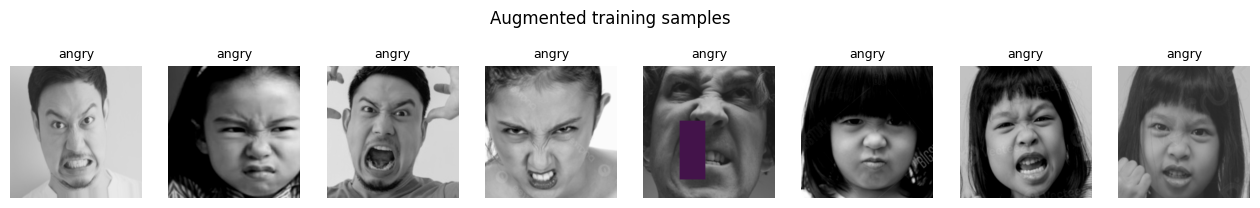

In [4]:
def gpu_augment(xb: torch.Tensor, a) -> torch.Tensor:
    """xb: B,3,S,S float in [0,1]. Face-safe: mild zoom/aspect/rotation/shift, h-flip, brightness/contrast, erasing."""
    B, dev = xb.shape[0], xb.device
    area = torch.empty(B, device=dev).uniform_(a.crop_scale_min, 1.0)
    logr = torch.empty(B, device=dev).uniform_(math.log(0.85), math.log(1 / 0.85))
    sx = (area * torch.exp(logr)).sqrt().clamp(max=1.0)
    sy = (area / torch.exp(logr)).sqrt().clamp(max=1.0)
    ang = torch.empty(B, device=dev).uniform_(-a.degrees, a.degrees) * math.pi / 180
    flip = torch.where(torch.rand(B, device=dev) < 0.5, -1.0, 1.0)
    tx = (torch.rand(B, device=dev) * 2 - 1) * (1 - sx)
    ty = (torch.rand(B, device=dev) * 2 - 1) * (1 - sy)
    cos, sin = torch.cos(ang), torch.sin(ang)
    theta = torch.stack([
        torch.stack([cos * sx * flip, -sin * sy, tx], 1),
        torch.stack([sin * sx * flip, cos * sy, ty], 1),
    ], 1)
    grid = F.affine_grid(theta, xb.shape, align_corners=False)
    xb = F.grid_sample(xb, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
    # photometric
    c = torch.empty(B, 1, 1, 1, device=dev).uniform_(0.75, 1.25)
    b = torch.empty(B, 1, 1, 1, device=dev).uniform_(-0.12, 0.12)
    m = xb.mean(dim=(1, 2, 3), keepdim=True)
    xb = ((xb - m) * c + m + b).clamp_(0, 1)
    # random erasing
    if a.erasing > 0:
        S = xb.shape[-1]
        for i in torch.nonzero(torch.rand(B, device=dev) < a.erasing).flatten().tolist():
            ar = np.random.uniform(0.02, 0.2) * S * S
            rr = math.exp(np.random.uniform(math.log(0.4), math.log(2.5)))
            h, w = int(min(S, round(math.sqrt(ar * rr)))), int(min(S, round(math.sqrt(ar / rr))))
            t, l = np.random.randint(0, S - h + 1), np.random.randint(0, S - w + 1)
            xb[i, :, t:t + h, l:l + w] = torch.rand(3, 1, 1, device=dev)
    return xb


def mix(xb, yb, a):
    """Returns mixed images and soft targets (label smoothing applied)."""
    tgt = F.one_hot(yb, NC).float() * (1 - a.label_smoothing) + a.label_smoothing / NC
    r = np.random.rand()
    if r < a.mixup_prob:
        lam = np.random.beta(a.mixup_alpha, a.mixup_alpha)
        perm = torch.randperm(xb.shape[0], device=xb.device)
        xb = lam * xb + (1 - lam) * xb[perm]
        tgt = lam * tgt + (1 - lam) * tgt[perm]
    elif r < a.mixup_prob + a.cutmix_prob:
        lam = np.random.beta(a.cutmix_alpha, a.cutmix_alpha)
        perm = torch.randperm(xb.shape[0], device=xb.device)
        S = xb.shape[-1]
        h, w = int(S * math.sqrt(1 - lam)), int(S * math.sqrt(1 - lam))
        t, l = np.random.randint(0, S - h + 1), np.random.randint(0, S - w + 1)
        xb = xb.clone()
        xb[:, :, t:t + h, l:l + w] = xb[perm][:, :, t:t + h, l:l + w]
        lam = 1 - h * w / (S * S)
        tgt = lam * tgt + (1 - lam) * tgt[perm]
    return xb, tgt


_ib = torch.as_tensor(idx_tr[:8], device="cuda")
_demo = gpu_augment(X[_ib].float().div_(255), a).permute(0, 2, 3, 1).cpu().numpy()
fig, axes = plt.subplots(1, 8, figsize=(16, 2.2))
for ax, im, yi in zip(axes, _demo, Y[idx_tr[:8]]):
    ax.imshow(im); ax.set_title(CLASS_NAMES[yi], fontsize=9); ax.axis("off")
plt.suptitle("Augmented training samples", y=1.05); plt.show()

## 5. Model, EMA and training loop

In [5]:
def new_model(a):
    from ultralytics import YOLO
    from ultralytics.nn.tasks import ClassificationModel

    yolo = YOLO(a.weights)
    m = yolo.model
    ClassificationModel.reshape_outputs(m, NC)
    m.names = dict(enumerate(CLASS_NAMES))
    m.nc = NC
    if isinstance(getattr(m, "yaml", None), dict):
        m.yaml["nc"] = NC
    for p in m.parameters():
        p.requires_grad_(True)
    for mod in m.modules():
        if isinstance(mod, torch.nn.Dropout):
            mod.p = a.dropout
    return yolo, m.float().cuda()  # NCHW: channels_last is ~5x slower for this net on this GPU


class EMA:
    def __init__(self, model, decay):
        self.ema = copy.deepcopy(model).eval()
        for p in self.ema.parameters():
            p.requires_grad_(False)
        self.decay, self.n = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = self.decay * (1 - math.exp(-self.n / 500))
        msd = model.state_dict()
        for k, v in self.ema.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else:
                v.copy_(msd[k])


@torch.no_grad()
def predict(model, X, idx, flip_tta=False, bs=256):
    """Class probabilities for X[idx] (uint8 tensor on GPU)."""
    model.eval()
    out = []
    for i in range(0, len(idx), bs):
        xb = X[idx[i:i + bs]].float().div_(255)
        with torch.autocast("cuda", dtype=torch.float16):
            o = model(xb)
            o = o[0] if isinstance(o, (tuple, list)) else o  # eval -> (softmax probs, logits)
            if flip_tta:
                o2 = model(xb.flip(-1))
                o = (o + (o2[0] if isinstance(o2, (tuple, list)) else o2)) / 2
        out.append(o.float())
    p = torch.cat(out)
    if not torch.allclose(p.sum(1), torch.ones_like(p[:, 0]), atol=1e-2):
        p = p.softmax(1)
    return p.cpu().numpy()


def train_one(a, X, Y, tr_idx, epochs, val_idx=None, tag=""):
    """Returns (yolo wrapper, best/final EMA model, history). Selects best epoch on val_idx if given."""
    yolo, model = new_model(a)
    ema = EMA(model, a.ema_decay)
    decay, no_decay = [], []
    for n, p in model.named_parameters():
        (no_decay if p.ndim <= 1 else decay).append(p)
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": a.weight_decay},
                             {"params": no_decay, "weight_decay": 0.0}], lr=a.lr0, betas=(0.9, 0.999))
    scaler = torch.amp.GradScaler("cuda")
    steps_per_epoch = len(tr_idx) // a.batch
    total, warm = epochs * steps_per_epoch, int(a.warmup_epochs * steps_per_epoch)
    tr = torch.as_tensor(tr_idx, device="cuda")
    Yg = torch.as_tensor(Y, device="cuda")
    best_acc, best_state, best_epoch, hist, step = -1.0, None, 0, [], 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        perm = tr[torch.randperm(len(tr), device="cuda")]
        run_loss = 0.0
        for bi in range(steps_per_epoch):  # drop last
            lr = a.lr0 * (step + 1) / warm if step < warm else \
                a.lr_min + 0.5 * (a.lr0 - a.lr_min) * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
            for g in opt.param_groups:
                g["lr"] = lr
            ib = perm[bi * a.batch:(bi + 1) * a.batch]
            xb = gpu_augment(X[ib].float().div_(255), a)
            xb, tgt = mix(xb, Yg[ib], a)
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(xb)
            loss = torch.sum(-tgt * F.log_softmax(logits.float(), 1), 1).mean()
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt)
            scaler.update()
            ema.update(model)
            run_loss += loss.item()
            step += 1
        row = {"epoch": ep, "time": time.time() - t0, "train_loss": run_loss / steps_per_epoch, "lr": lr}
        if val_idx is not None:
            pv = predict(ema.ema, X, val_idx)
            acc = float((pv.argmax(1) == Y[val_idx]).mean())
            vloss = float(-np.log(np.clip(pv[np.arange(len(val_idx)), Y[val_idx]], 1e-9, 1)).mean())
            row.update(val_acc=acc, val_loss=vloss)
            if acc > best_acc:
                best_acc, best_epoch = acc, ep
                best_state = copy.deepcopy(ema.ema.state_dict())
        hist.append(row)
        print(f"[{tag}] " + " ".join(f"{k}={v:.5g}" if isinstance(v, float) else f"{k}={v}" for k, v in row.items()),
              flush=True)
    if best_state is not None:
        ema.ema.load_state_dict(best_state)
    return yolo, ema.ema, pd.DataFrame(hist), best_epoch

## 6. Label-audit helpers

In [6]:
def confident_learning_flags(P: np.ndarray, Y: np.ndarray):
    """Confident-learning rule (Northcutt et al., 2021): flag i when its given label is below that class's
    mean self-confidence threshold AND another class is at/above its own threshold."""
    thr = np.array([P[Y == k, k].mean() for k in range(NC)])
    above = P >= thr[None]
    above[np.arange(len(Y)), Y] = False
    masked = np.where(above, P, -1.0)
    sugg = masked.argmax(1)
    flag = above.any(1) & (P[np.arange(len(Y)), Y] < thr[Y])
    return flag, sugg, thr


def contact_sheet(df, path, n=96, cols=12, s=128):
    df = df.head(n)
    rows = max(1, (len(df) + cols - 1) // cols)
    canvas = Image.new("RGB", (cols * s, rows * (s + 26)), "white")
    d = ImageDraw.Draw(canvas)
    for i, r in enumerate(df.itertuples()):
        im = Image.open(r.crop_path).convert("RGB").resize((s, s))
        x, y = (i % cols) * s, (i // cols) * (s + 26)
        canvas.paste(im, (x, y))
        d.text((x + 2, y + s + 1), f"label: {r.given_label}", fill="green")
        d.text((x + 2, y + s + 13), f"oof: {r.suggested_label} {r.oof_prob_suggested:.2f}", fill="red")
    canvas.save(path, quality=88)


def wilson(acc, n, z=1.959963984540054):
    den = 1 + z * z / n
    c = (acc + z * z / (2 * n)) / den
    h = z * math.sqrt(acc * (1 - acc) / n + z * z / (4 * n * n)) / den
    return [c - h, c + h]


def report(y, p, mask=None):
    if mask is not None:
        y, p = y[mask], p[mask]
    pred = p.argmax(1)
    acc = float((pred == y).mean())
    cm = confusion_matrix(y, pred, labels=np.arange(NC))
    return {
        "images": int(len(y)),
        "accuracy": acc,
        "macro_f1": float(f1_score(y, pred, average="macro")),
        "accuracy_wilson_95_ci": wilson(acc, len(y)),
        "per_class_accuracy": {c: float(cm[i, i] / max(1, cm[i].sum())) for i, c in enumerate(CLASS_NAMES)},
        "confusion_matrix": cm.tolist(),
        "classification_report": classification_report(y, pred, labels=np.arange(NC), target_names=CLASS_NAMES,
                                                       output_dict=True, zero_division=0),
    }

## 7. Stage 1 - out-of-fold label audit

Skipped when an existing `label_audit.csv` is reused. Flagged images are only *excluded from training and from
the audited metric*; the original files and labels are untouched. Review `flagged_*.jpg` / `label_audit.csv`.

Reusing D:\Shitol\last_codes\outputs\yolov8m_finetuned\runs\yolov8m_noise_robust_nb_20261111_191527\label_audit.csv
Out-of-fold accuracy on all 21541 images: 0.9116


,flagged,fraction
split,,
train,372,0.024672
val,78,0.024134
test,74,0.022903


,flagged,fraction
given_label,,
angry,98,0.029661
fear,76,0.035072
happy,63,0.012912
neutral,80,0.019259
sad,108,0.027349
surprise,99,0.032060


Random sample of flagged TEST images (green = given label, red = out-of-fold prediction):


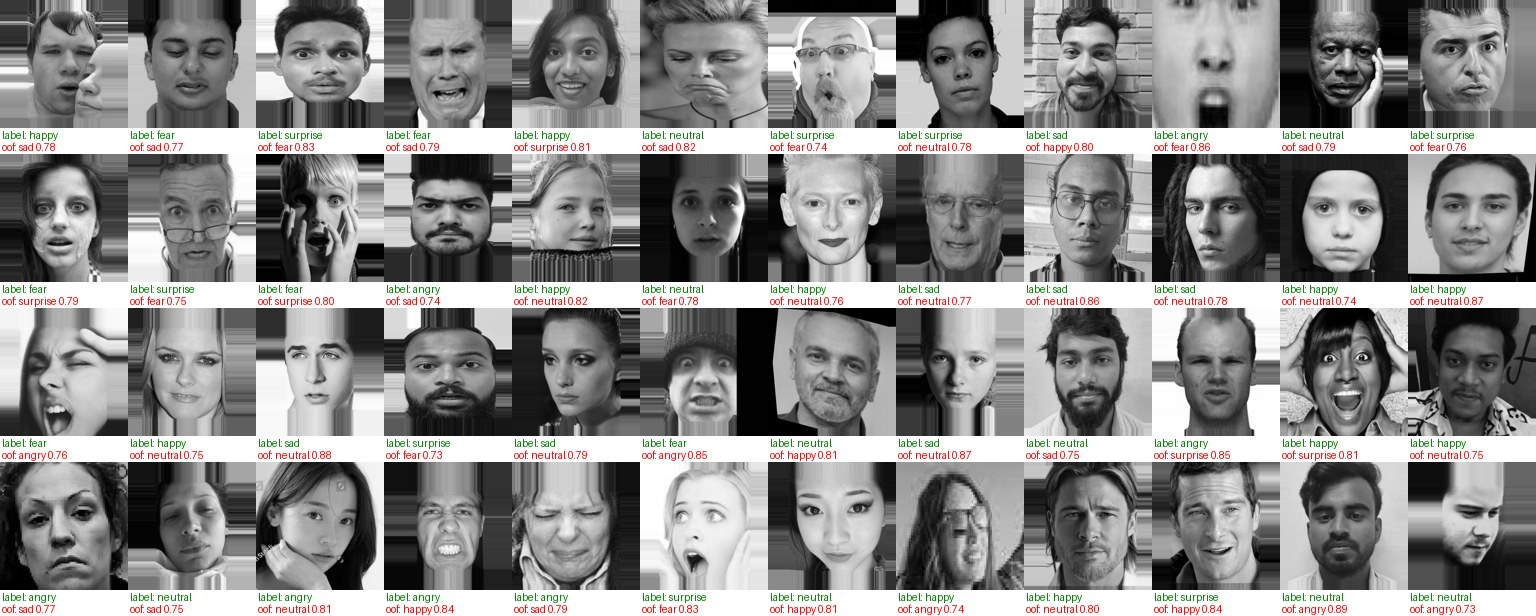

In [7]:
audit = None
if not USE_AUDIT:
    flag = np.zeros(len(df), bool)
elif AUDIT_CSV:
    audit = pd.read_csv(AUDIT_CSV)
    flag = df.idx.map(audit.set_index("idx").flagged).fillna(False).values.astype(bool)
    print(f"Reusing {AUDIT_CSV}")
else:
    P = np.zeros((len(df), NC), np.float32)
    skf = StratifiedGroupKFold(n_splits=a.folds, shuffle=True, random_state=a.seed)
    for k, (tr, ho) in enumerate(skf.split(np.zeros(len(df)), Y, groups=df.group.values)):
        _, m, _, _ = train_one(a, X, Y, tr, a.oof_epochs, val_idx=None, tag=f"oof{k}")
        P[ho] = predict(m, X, ho, flip_tta=True)
        print(f"[oof{k}] held-out acc = {(P[ho].argmax(1) == Y[ho]).mean():.4f}", flush=True)
        del m
        torch.cuda.empty_cache()
    flag, sugg, thr = confident_learning_flags(P, Y)
    audit = pd.DataFrame({
        "idx": df.idx, "crop_path": df.crop_path, "source_path": df.source_path, "split": df.split,
        "given_label": [CLASS_NAMES[i] for i in Y], "oof_pred": [CLASS_NAMES[i] for i in P.argmax(1)],
        "oof_prob_given": P[np.arange(len(Y)), Y], "flagged": flag,
        "suggested_label": np.where(flag, np.array(CLASS_NAMES)[sugg], ""),
        "oof_prob_suggested": np.where(flag, P[np.arange(len(Y)), sugg], np.nan),
    })
    for i, c in enumerate(CLASS_NAMES):
        audit[f"oof_p_{c}"] = P[:, i]
    audit.to_csv(RUN_DIR / "label_audit.csv", index=False)
    print("Class thresholds:", dict(zip(CLASS_NAMES, thr.round(3))))

if audit is not None:
    print(f"Out-of-fold accuracy on all {len(audit)} images: {(audit.oof_pred == audit.given_label).mean():.4f}")
    display(audit.groupby("split").flagged.agg(flagged="sum", fraction="mean").loc[["train", "val", "test"]])
    display(audit.groupby("given_label").flagged.agg(flagged="sum", fraction="mean"))
    sub = audit[(audit.split == "test") & audit.flagged].sort_values("oof_prob_suggested", ascending=False)
    for s in ("val", "test", "train"):
        ss = audit[(audit.split == s) & audit.flagged].sort_values("oof_prob_suggested", ascending=False)
        contact_sheet(ss, RUN_DIR / f"flagged_{s}_most_confident.jpg")
    contact_sheet(sub.sample(min(48, len(sub)), random_state=0), RUN_DIR / "flagged_test_random.jpg", n=48)
    print("Random sample of flagged TEST images (green = given label, red = out-of-fold prediction):")
    display(Image.open(RUN_DIR / "flagged_test_random.jpg"))

## 8. Stage 2 - final fine-tune

In [8]:
tr_clean = idx_tr[~flag[idx_tr]]
va_clean = idx_va[~flag[idx_va]]
print(f"train {len(idx_tr)} -> {len(tr_clean)} | validation used for epoch selection {len(idx_va)} -> {len(va_clean)}")
yolo, model, hist, best_epoch = train_one(a, X, Y, tr_clean, a.epochs, val_idx=va_clean, tag="final")
hist.to_csv(RUN_DIR / "results.csv", index=False)

train 15078 -> 14706 | validation used for epoch selection 3232 -> 3154


[final] epoch=1 time=18.835 train_loss=1.5092 lr=0.00025 val_acc=0.72511 val_loss=0.83351


[final] epoch=2 time=40.836 train_loss=1.1267 lr=0.0005 val_acc=0.81674 val_loss=0.64253


[final] epoch=3 time=52.982 train_loss=1.023 lr=0.00049934 val_acc=0.83798 val_loss=0.54443


[final] epoch=4 time=65.154 train_loss=0.93924 lr=0.00049735 val_acc=0.87127 val_loss=0.49703


[final] epoch=5 time=77.314 train_loss=0.94113 lr=0.00049405 val_acc=0.89157 val_loss=0.45663


... (36 outputs left out)

[final] epoch=42 time=527.58 train_loss=0.7003 lr=6.9864e-06 val_acc=0.92803 val_loss=0.35168


[final] epoch=43 time=539.75 train_loss=0.68926 lr=3.6704e-06 val_acc=0.92803 val_loss=0.35115


[final] epoch=44 time=551.94 train_loss=0.72327 lr=1.6714e-06 val_acc=0.92834 val_loss=0.35367


[final] epoch=45 time=564.1 train_loss=0.68263 lr=1e-06 val_acc=0.92771 val_loss=0.35422


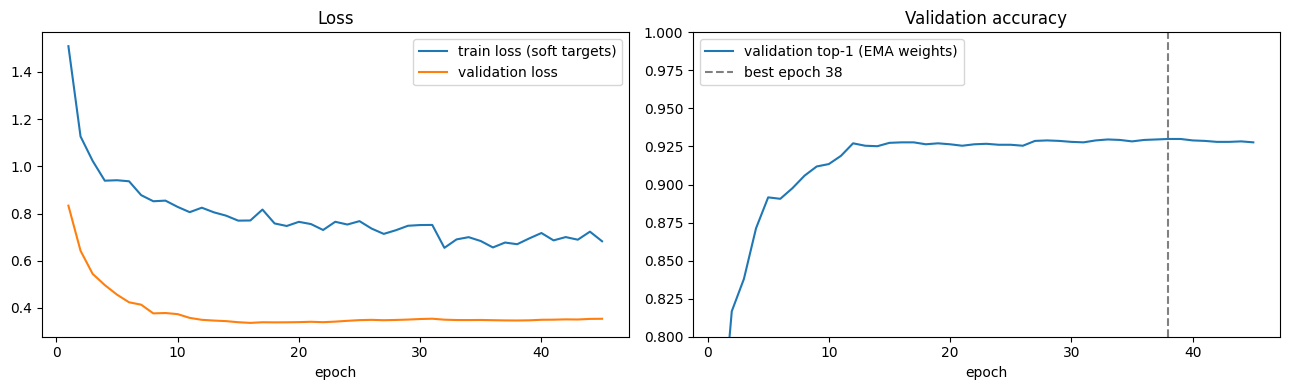

Best epoch 38 | validation top-1 0.9299 | training time 9.4 min


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hist.epoch, hist.train_loss, label="train loss (soft targets)")
axes[0].plot(hist.epoch, hist.val_loss, label="validation loss")
axes[0].set(title="Loss", xlabel="epoch"); axes[0].legend()
axes[1].plot(hist.epoch, hist.val_acc, label="validation top-1 (EMA weights)")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch {best_epoch}")
axes[1].set(title="Validation accuracy", xlabel="epoch", ylim=(0.8, 1.0)); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Best epoch {best_epoch} | validation top-1 {hist.val_acc.max():.4f} | training time {hist.time.iloc[-1] / 60:.1f} min")

## 9. Evaluation

Flip-TTA is chosen on validation only. The test split was already read by earlier runs, so treat every test
figure here as exploratory.

Flip TTA selected on validation: True
Validation: {"all_labels_single_view": 0.9112, "all_labels_flip_tta": 0.9162, "audited_single_view": 0.9299, "audited_flip_tta": 0.9353, "flagged": 78}
TEST - all original labels : accuracy 0.9155 | macro-F1 0.9119 | n=3231 | 95% CI [0.9054, 0.9246]
TEST - audited subset      : accuracy 0.9354 | macro-F1 0.9324 | n=3157 (74 flagged images excluded)
Previous YOLOv8m test accuracy (all original labels): 0.9056


,all original labels,audited subset
angry,0.9010,0.9136
fear,0.8708,0.9010
happy,0.9617,0.9791
neutral,0.9246,0.9426
sad,0.9022,0.9224
surprise,0.8942,0.9200


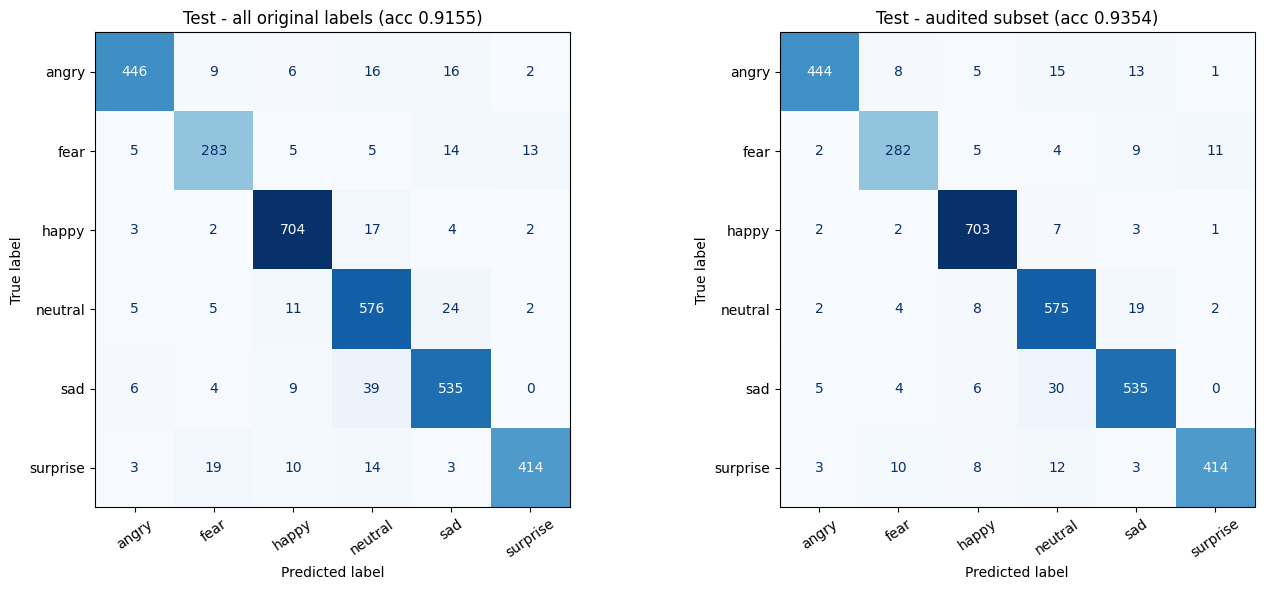

In [10]:
pv, pv_f = predict(model, X, idx_va), predict(model, X, idx_va, flip_tta=True)
acc = lambda p, idx, m=None: float((p.argmax(1) == Y[idx])[m if m is not None else slice(None)].mean())
vmask, tmask = ~flag[idx_va], ~flag[idx_te]
use_tta = acc(pv_f, idx_va, vmask) > acc(pv, idx_va, vmask)
pt = predict(model, X, idx_te, flip_tta=use_tta)

metrics = {
    "model": "yolov8m-cls", "init_weights": a.weights, "img_size": a.imgsz, "best_epoch": int(best_epoch),
    "epochs_run": int(len(hist)), "train_minutes": float(hist.time.iloc[-1] / 60),
    "flip_tta_selected_on_validation": bool(use_tta),
    "train_images_used": int(len(tr_clean)), "train_images_flagged_removed": int(len(idx_tr) - len(tr_clean)),
    "validation": {
        "all_labels_single_view": acc(pv, idx_va), "all_labels_flip_tta": acc(pv_f, idx_va),
        "audited_single_view": acc(pv, idx_va, vmask), "audited_flip_tta": acc(pv_f, idx_va, vmask),
        "flagged": int((~vmask).sum()),
    },
    "test_all_original_labels": report(Y[idx_te], pt),
    "test_audited_subset": report(Y[idx_te], pt, tmask),
    "test_flagged_excluded": int((~tmask).sum()),
    "note": "test_all_original_labels is the only figure comparable with earlier runs. test_audited_subset "
            "excludes test images flagged by out-of-fold confident learning (models that never trained on "
            "them); flagged images were not human-verified, so treat it as an optimistic estimate.",
    "baseline_test_accuracy": 0.9056, "target_test_accuracy": 0.95,
}
metrics["target_achieved_all_original_labels"] = bool(metrics["test_all_original_labels"]["accuracy"] >= 0.95)
metrics["target_achieved_audited_subset"] = bool(metrics["test_audited_subset"]["accuracy"] >= 0.95)

t, s = metrics["test_all_original_labels"], metrics["test_audited_subset"]
print("Flip TTA selected on validation:", use_tta)
print("Validation:", json.dumps({k: round(v, 4) for k, v in metrics["validation"].items()}))
print(f"TEST - all original labels : accuracy {t['accuracy']:.4f} | macro-F1 {t['macro_f1']:.4f} | n={t['images']} "
      f"| 95% CI [{t['accuracy_wilson_95_ci'][0]:.4f}, {t['accuracy_wilson_95_ci'][1]:.4f}]")
print(f"TEST - audited subset      : accuracy {s['accuracy']:.4f} | macro-F1 {s['macro_f1']:.4f} | n={s['images']} "
      f"({metrics['test_flagged_excluded']} flagged images excluded)")
print("Previous YOLOv8m test accuracy (all original labels): 0.9056")
display(pd.DataFrame({"all original labels": t["per_class_accuracy"], "audited subset": s["per_class_accuracy"]}).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, rep, title in ((axes[0], t, "all original labels"), (axes[1], s, "audited subset")):
    ConfusionMatrixDisplay(np.array(rep["confusion_matrix"]), display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", xticks_rotation=35, colorbar=False)
    ax.set_title(f"Test - {title} (acc {rep['accuracy']:.4f})")
plt.tight_layout(); plt.show()

## 10. Save metrics, predictions and an Ultralytics-loadable checkpoint

In [11]:
json.dump(metrics, open(RUN_DIR / "metrics.json", "w"), indent=2)
te = df.iloc[idx_te]
pred = pd.DataFrame({"path": te.crop_path.values, "true_label": [CLASS_NAMES[i] for i in Y[idx_te]],
                     "predicted_label": [CLASS_NAMES[i] for i in pt.argmax(1)], "confidence": pt.max(1),
                     "flagged_by_label_audit": flag[idx_te]})
for i, c in enumerate(CLASS_NAMES):
    pred[f"prob_{c}"] = pt[:, i]
pred.to_csv(RUN_DIR / "test_predictions.csv", index=False)
pd.DataFrame(t["confusion_matrix"], index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RUN_DIR / "test_confusion_matrix.csv")

(RUN_DIR / "weights").mkdir(exist_ok=True)
BEST_PT = RUN_DIR / "weights" / "best.pt"
yolo.model = copy.deepcopy(model).float().cpu()
yolo.model.names = dict(enumerate(CLASS_NAMES))
if isinstance(yolo.ckpt, dict):
    yolo.ckpt.pop("ema", None)
    yolo.ckpt.pop("optimizer", None)
yolo.overrides["imgsz"] = a.imgsz
yolo.save(str(BEST_PT))

# sanity check: reload through the normal Ultralytics API
from ultralytics import YOLO
chk = YOLO(str(BEST_PT))
sample = te.sample(200, random_state=0)
res = chk.predict(sample.crop_path.tolist(), imgsz=a.imgsz, verbose=False)
agree = np.mean([r.probs.top1 == CLASS_NAMES.index(p) for r, p in
                 zip(res, pred.set_index("path").loc[sample.crop_path, "predicted_label"])])
print(f"Checkpoint: {BEST_PT}")
print(f"YOLO(best.pt).predict agrees with this notebook on {agree:.1%} of 200 test images (single view)")
print("Saved:", RUN_DIR)

Checkpoint: D:\Shitol\last_codes\outputs\yolov8m_finetuned\runs\yolov8m_noise_robust_nb_20261111_215518\weights\best.pt
YOLO(best.pt).predict agrees with this notebook on 99.0% of 200 test images (single view)
Saved: D:\Shitol\last_codes\outputs\yolov8m_finetuned\runs\yolov8m_noise_robust_nb_20261111_215518


## Notes

* Load the model with `YOLO("<run>/weights/best.pt").predict(source, imgsz=256)`.
* Only **test - all original labels** is comparable with the earlier YOLO11 / YOLOv8m results.
* The audited-subset figure depends on the flagged list. Before quoting it, review `flagged_test_*.jpg` and
  `label_audit.csv` and correct or confirm the labels by hand; a model-only audit removes hard-but-correct images
  along with genuine label errors.
* The fine-tuning parameters are all in section 2.